In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

## Data Preperation

In [ ]:
csv_file_name = "data/logs/Video Mar 12 2026, 8 25 01 AM.csv" # you can just copy&paste relative path
df = pd.read_csv(f"../{csv_file_name}")

In [3]:
# Drop rows with "unknown" light_state or handle it
df = df[df["light_state"] != "unknown"]
# Encode light_state as categorical
df["light_state_enc"] = pd.Categorical(df["light_state"]).codes

In [4]:
X = df[["class", "dist", "delta_dist", "light_state_enc"]]
y = df["is_safe"]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

## Models

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [6]:
models = {
    "Logistic Regression": LogisticRegression(), # base model
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"\n{name}")
    print("Accuracy: ", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:   ", recall_score(y_test, y_pred))
    print("F1:       ", f1_score(y_test, y_pred))
    print("ROC-AUC:  ", roc_auc_score(y_test, model.predict_proba(X_test)[:,1]))


Logistic Regression
Accuracy:  0.9228187919463087
Precision: 0.8032786885245902
Recall:    0.5903614457831325
F1:        0.6805555555555556
ROC-AUC:   0.8774865544047535

Decision Tree
Accuracy:  0.9530201342281879
Precision: 0.9661016949152542
Recall:    0.6867469879518072
F1:        0.8028169014084507
ROC-AUC:   0.9623758190657367

Random Forest
Accuracy:  0.9530201342281879
Precision: 0.9661016949152542
Recall:    0.6867469879518072
F1:        0.8028169014084507
ROC-AUC:   0.9679771718452759


## Visualizations

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
import matplotlib.pyplot as plt

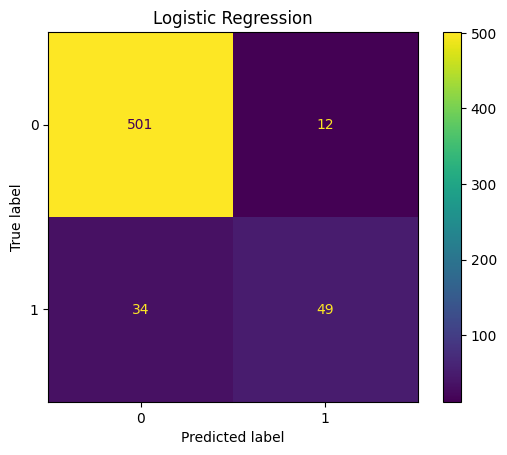

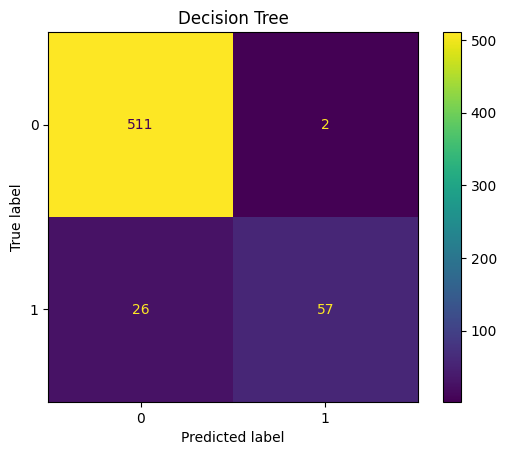

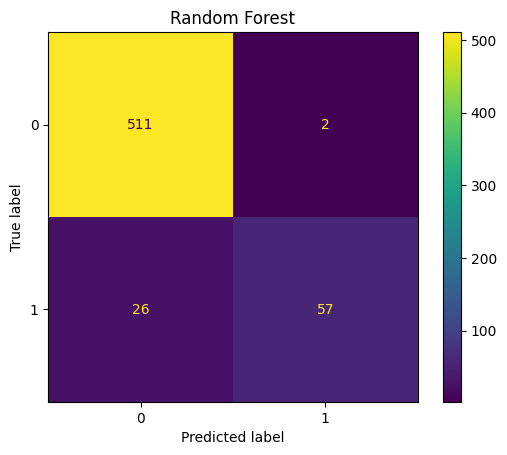

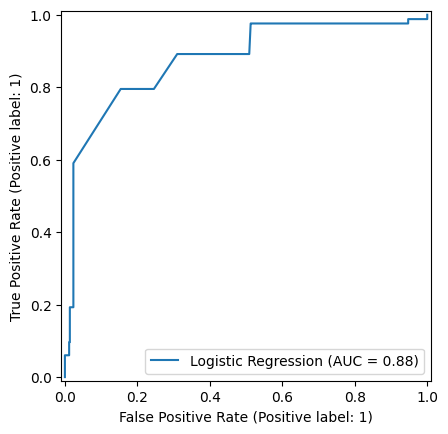

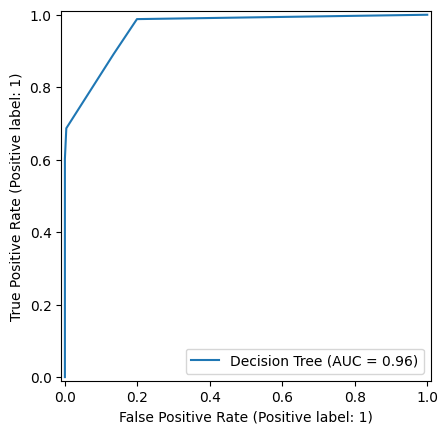

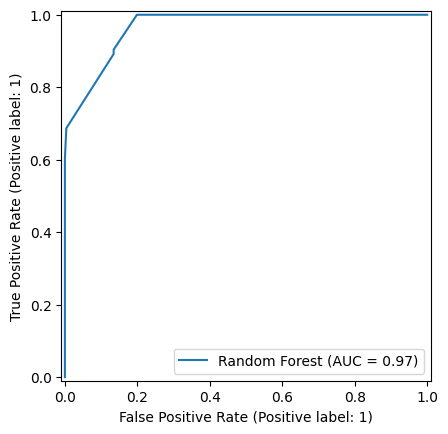

In [8]:
# Confusion matrix for each model
for name, model in models.items():
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test)
    plt.title(name)
    plt.show()

# ROC curves together
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name)
plt.show()